Total mass: 720.7936464511091
Number of nodes: 297


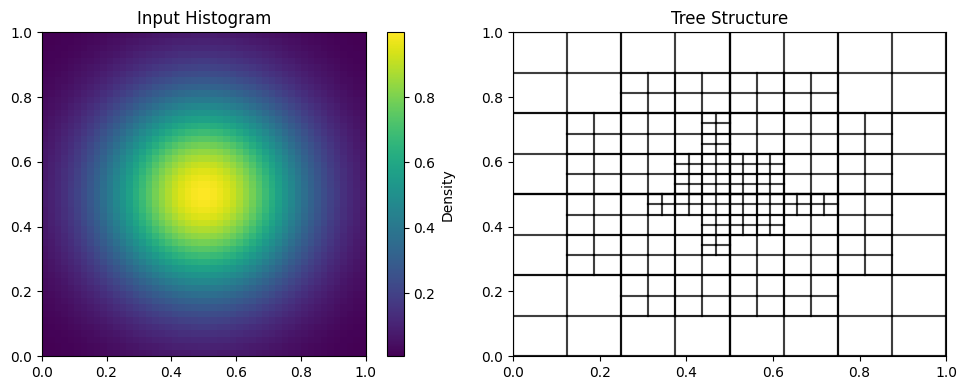

Data generated and histogram computed.
Statistics for Depth-based Alpha:
Tree posterior/area - Min: 1.536, Max: 27874.645
Tree posterior/area - Mean: 4741.560
Statistics for Density-based Alpha:
Tree posterior/area - Min: 1.504, Max: 15204.352
Tree posterior/area - Mean: 2608.584
Statistics for Curvature-based Alpha:
Tree posterior/area - Min: 1.122, Max: 2272746.537
Tree posterior/area - Mean: 172975.148
Statistics for Hybrid Alpha:
Tree posterior/area - Min: 1.958, Max: 27874.645
Tree posterior/area - Mean: 4750.218


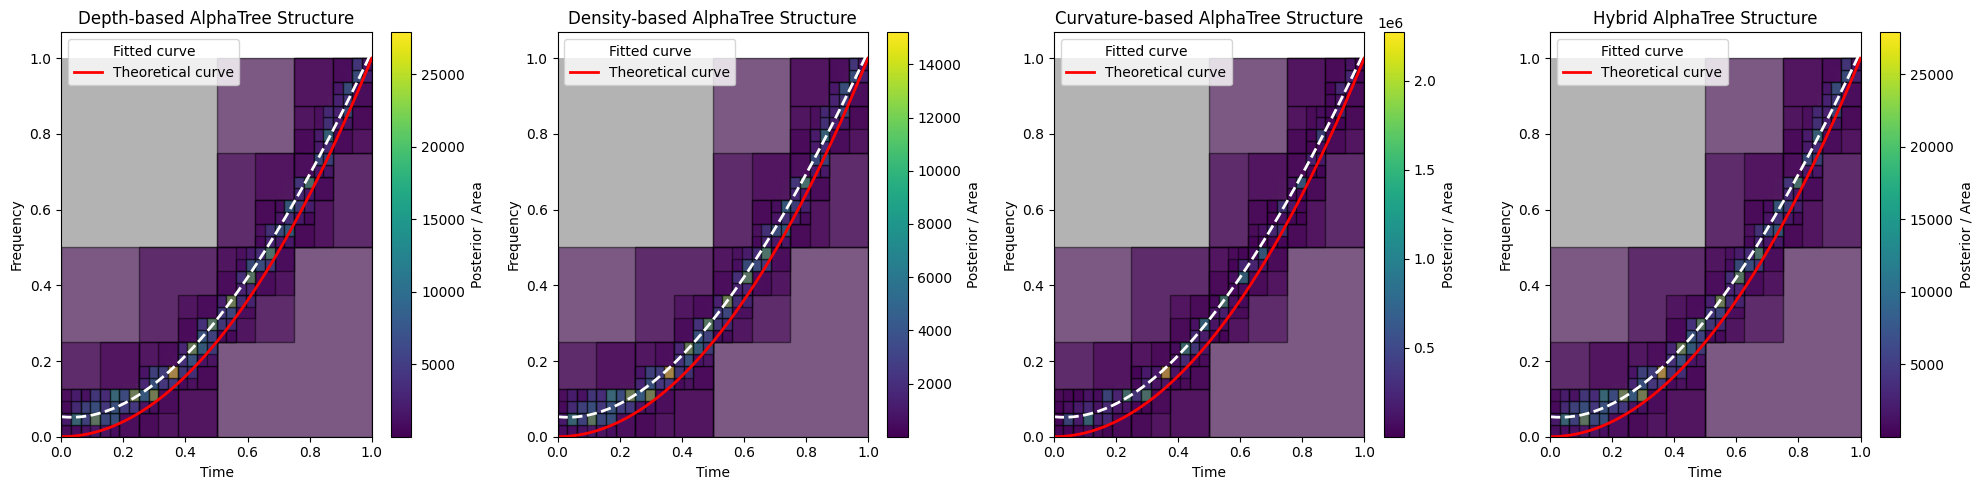

In [18]:
import numpy as np

class AdaptiveBivariatePolyaTreeMultiAlpha:
    def __init__(self, base_depth=4, max_depth=8, density_threshold=0.01, min_mass=0.01, 
                 alpha0=0.5, lam=1.0, beta=0.5, gamma=2.0, eta=1.0, domain=((0, 1), (0, 1))):
        self.base_depth = base_depth
        self.max_depth = max_depth
        self.density_threshold = density_threshold
        self.min_mass = min_mass  # Changed from min_points to min_mass for histogram
        self.alpha0 = alpha0
        self.lam = lam
        self.beta = beta
        self.gamma = gamma
        self.eta = eta
        self.domain = domain
        self.counts = {}
        self.counts[()] = 0
        self.total_mass = 0  # Changed from total_points to total_mass
        
    def _get_quadrant(self, x, y, x_mid, y_mid):
        if x <= x_mid:
            return 0 if y <= y_mid else 1
        else:
            return 2 if y <= y_mid else 3
    
    def _get_node_bounds(self, node):
        x_left, x_right = self.domain[0]
        y_bottom, y_top = self.domain[1]
        for q in node:
            x_mid = (x_left + x_right) / 2.0
            y_mid = (y_bottom + y_top) / 2.0
            if q in [0, 1]:
                x_right = x_mid
            else:
                x_left = x_mid
            if q in [0, 2]:
                y_top = y_mid
            else:
                y_bottom = y_mid
        return (x_left, x_right), (y_bottom, y_top)
    
    def _compute_local_density(self, node):
        (x_left, x_right), (y_bottom, y_top) = self._get_node_bounds(node)
        area = (x_right - x_left) * (y_top - y_bottom)
        count = self.counts.get(node, 0)
        return count / (self.total_mass * area) if area > 0 else 0
    
    def _should_split(self, node, mass, input_pixel_size):
        if len(node) >= self.max_depth:
            return False
            
        # Get current node dimensions
        (x_left, x_right), (y_bottom, y_top) = self._get_node_bounds(node)
        node_width = x_right - x_left
        node_height = y_top - y_bottom
        
        # Check if splitting would create cells smaller than input pixels
        if node_width/2 < input_pixel_size[0] or node_height/2 < input_pixel_size[1]:
            return False
            
        if len(node) < self.base_depth:
            return True
            
        density = self._compute_local_density(node)
        return (mass >= self.min_mass * self.total_mass and 
                density >= self.density_threshold and 
                len(node) < self.max_depth)
    
    def _update_counts_from_histogram(self, hist_2d, input_pixel_size):
        """Update counts using 2D histogram data"""
        self.total_mass = np.sum(hist_2d)
        
        # Get histogram dimensions
        ny, nx = hist_2d.shape
        dx = (self.domain[0][1] - self.domain[0][0]) / nx
        dy = (self.domain[1][1] - self.domain[1][0]) / ny
        
        points_to_process = [((), hist_2d)]
        while points_to_process:
            node, node_hist = points_to_process.pop(0)
            
            # Compute mass in current node
            self.counts[node] = np.sum(node_hist)
            
            if self._should_split(node, self.counts[node], input_pixel_size):
                # Split histogram into quadrants
                ny, nx = node_hist.shape
                mid_y, mid_x = ny//2, nx//2
                
                quadrants = {
                    0: node_hist[:mid_y, :mid_x],
                    1: node_hist[mid_y:, :mid_x],
                    2: node_hist[:mid_y, mid_x:],
                    3: node_hist[mid_y:, mid_x:]
                }
                
                for q in range(4):
                    if np.sum(quadrants[q]) > 0:  # Only process non-empty quadrants
                        points_to_process.append((node + (q,), quadrants[q]))
    
    def fit(self, hist_2d):
        """Fit the Polya tree using a 2D histogram"""
        # Calculate input pixel size
        ny, nx = hist_2d.shape
        dx = (self.domain[0][1] - self.domain[0][0]) / nx
        dy = (self.domain[1][1] - self.domain[1][0]) / ny
        input_pixel_size = (dx, dy)
        
        self._update_counts_from_histogram(hist_2d, input_pixel_size)
        return self

# Test the modified class with a simple example
if __name__ == "__main__":
    # Create a simple test histogram
    nx, ny = 50, 50
    x = np.linspace(0, 1, nx)
    y = np.linspace(0, 1, ny)
    X, Y = np.meshgrid(x, y)
    
    # Create a simple gaussian bump
    hist_2d = np.exp(-((X-0.5)**2 + (Y-0.5)**2)/0.1)
    
    # Initialize and fit the tree
    tree = AdaptiveBivariatePolyaTreeMultiAlpha(
        base_depth=2,
        max_depth=6,
        density_threshold=0.01,
        min_mass=0.01
    )
    tree.fit(hist_2d)
    
    # Print some basic information
    print("Total mass:", tree.total_mass)
    print("Number of nodes:", len(tree.counts))
    
    # Plot the input histogram
    import matplotlib.pyplot as plt
    
    plt.figure(figsize=(10, 4))
    
    plt.subplot(121)
    plt.imshow(hist_2d, origin='lower', extent=[0, 1, 0, 1])
    plt.colorbar(label='Density')
    plt.title('Input Histogram')
    
    # Plot the node structure
    plt.subplot(122)
    for node in tree.counts:
        if node:  # Skip root node
            (x_left, x_right), (y_bottom, y_top) = tree._get_node_bounds(node)
            plt.plot([x_left, x_right], [y_bottom, y_bottom], 'k-', alpha=0.5)
            plt.plot([x_left, x_right], [y_top, y_top], 'k-', alpha=0.5)
            plt.plot([x_left, x_left], [y_bottom, y_top], 'k-', alpha=0.5)
            plt.plot([x_right, x_right], [y_bottom, y_top], 'k-', alpha=0.5)
    
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.title('Tree Structure')
    
    plt.tight_layout()
    plt.show()

def generate_chirp_data(n_points=2000):
    # Generate clean theoretical curve first
    t_clean = np.linspace(0, 1, n_points)
    f_clean = 20 + 980 * t_clean**2
    
    # Generate noisy data
    t = t_clean + 0.02 * np.random.randn(n_points)
    f = f_clean + 20 * np.random.randn(n_points)
    
    # Normalize both clean and noisy data
    t = (t - t.min()) / (t.max() - t.min())
    f = (f - f.min()) / (f.max() - f.min())
    t_clean = (t_clean - t_clean.min()) / (t_clean.max() - t_clean.min())
    f_clean = (f_clean - f_clean.min()) / (f_clean.max() - f_clean.min())
    
    return np.column_stack([t, f]), np.column_stack([t_clean, f_clean])

class AdaptiveBivariatePolyaTreeMultiAlphaExtended(AdaptiveBivariatePolyaTreeMultiAlpha):
    def compute_posteriors_alphas(self, resolution=(50,50)):
        # Create grid centers using resolution
        nx, ny = resolution
        x = np.linspace(self.domain[0][0], self.domain[0][1], nx)
        y = np.linspace(self.domain[1][0], self.domain[1][1], ny)
        X, Y = np.meshgrid(x, y)
        
        densities = np.zeros_like(X)
        alpha_maps = {
            'depth': np.zeros_like(X),
            'density': np.zeros_like(X),
            'curvature': np.zeros_like(X),
            'hybrid': np.zeros_like(X)
        }
        normalized_alpha_maps = {
            'depth': np.zeros_like(X),
            'density': np.zeros_like(X),
            'curvature': np.zeros_like(X),
            'hybrid': np.zeros_like(X)
        }
        pixel_areas = np.zeros_like(X)
        
        for i in range(X.shape[0]):
            for j in range(X.shape[1]):
                x_pt, y_pt = X[i,j], Y[i,j]
                node = ()
                prob = 1.0
                while True:
                    (x_left, x_right), (y_bottom, y_top) = self._get_node_bounds(node)
                    area = (x_right - x_left) * (y_top - y_bottom)
                    pixel_areas[i,j] = area
                    
                    local_density = self._compute_local_density(node)
                    depth = len(node)
                    
                    # Compute different alpha definitions
                    alpha_depth = self.alpha0 * (1 + self.lam * depth / self.max_depth)
                    alpha_density = self.alpha0 * (1 + self.beta * np.exp(-self.gamma * local_density))
                    alpha_curvature = self.alpha0 * (1 + self.eta * abs(depth * local_density))
                    alpha_hybrid = alpha_depth * (1 + self.beta * np.exp(-self.gamma * local_density))
                    
                    # Store the alpha values
                    alpha_maps['depth'][i,j] = alpha_depth
                    alpha_maps['density'][i,j] = alpha_density
                    alpha_maps['curvature'][i,j] = alpha_curvature
                    alpha_maps['hybrid'][i,j] = alpha_hybrid
                    
                    normalized_alpha_maps['depth'][i,j] = alpha_depth / area if area>0 else 0
                    normalized_alpha_maps['density'][i,j] = alpha_density / area if area>0 else 0
                    normalized_alpha_maps['curvature'][i,j] = alpha_curvature / area if area>0 else 0
                    normalized_alpha_maps['hybrid'][i,j] = alpha_hybrid / area if area>0 else 0
                    
                    # Decide to split or not
                    mass = self.counts.get(node, 0)
                    input_dx = (self.domain[0][1] - self.domain[0][0]) / resolution[0]
                    input_dy = (self.domain[1][1] - self.domain[1][0]) / resolution[1]
                    input_pixel_size = (input_dx, input_dy)
                    
                    if not self._should_split(node, mass, input_pixel_size):
                        densities[i,j] = prob * local_density
                        break
                    
                    x_mid = (x_left + x_right)/2.0
                    y_mid = (y_bottom + y_top)/2.0
                    quadrant = self._get_quadrant(x_pt, y_pt, x_mid, y_mid)
                    node = node + (quadrant,)
                    prob /= 4.0

        return X, Y, densities, alpha_maps, normalized_alpha_maps, pixel_areas

# Generate data
points, clean_points = generate_chirp_data(n_points=2000)
nx, ny = 50, 50
hist_2d, x_edges, y_edges = np.histogram2d(
    points[:, 0], points[:, 1],
    bins=[nx, ny],
    range=[[0, 1], [0, 1]]
)
hist_2d = hist_2d.T

print("Data generated and histogram computed.")
tree_ext = AdaptiveBivariatePolyaTreeMultiAlphaExtended(
    base_depth=2,
    max_depth=6,
    density_threshold=0.01,
    min_mass=0.01
)
tree_ext.fit(hist_2d)
from scipy.stats import gaussian_kde
from scipy.interpolate import UnivariateSpline

def compute_tree_posteriors(tree, alpha_type='depth'):
    """Compute posteriors for each node using specified alpha type"""
    posterior_values = []
    rectangles = []
    points_for_kde = []
    
    for node in tree.counts:
        if node:
            (x_left, x_right), (y_bottom, y_top) = tree._get_node_bounds(node)
            area = (x_right - x_left) * (y_top - y_bottom)
            local_density = tree._compute_local_density(node)
            depth = len(node)
            
            if alpha_type == 'depth':
                alpha = tree.alpha0 * (1 + tree.lam * depth / tree.max_depth)
            elif alpha_type == 'density':
                alpha = tree.alpha0 * (1 + tree.beta * np.exp(-tree.gamma * local_density))
            elif alpha_type == 'curvature':
                alpha = tree.alpha0 * (1 + tree.eta * abs(depth * local_density))
            elif alpha_type == 'hybrid':
                alpha_depth = tree.alpha0 * (1 + tree.lam * depth / tree.max_depth)
                alpha = alpha_depth * (1 + tree.beta * np.exp(-tree.gamma * local_density))
            
            posterior = local_density * alpha
            posterior_per_area = posterior / area if area > 0 else 0
            
            # Store center point of the rectangle
            center_x = (x_left + x_right) / 2
            center_y = (y_bottom + y_top) / 2
            
            posterior_values.append(posterior_per_area)
            rectangles.append((x_left, y_bottom, x_right - x_left, y_top - y_bottom, posterior_per_area))
            points_for_kde.append([center_x, center_y, posterior_per_area])
            
    return np.array(posterior_values), rectangles, np.array(points_for_kde)

def extract_high_posterior_curve(points_for_kde, n_bins=20, threshold_percentile=90):
    """Extract the highest posterior frequency at each time bin"""
    times = points_for_kde[:, 0]
    freqs = points_for_kde[:, 1]
    posteriors = points_for_kde[:, 2]
    
    # Only consider points with high posterior (above threshold)
    threshold = np.percentile(posteriors, threshold_percentile)
    high_posterior_mask = posteriors >= threshold
    
    times_high = times[high_posterior_mask]
    freqs_high = freqs[high_posterior_mask]
    posteriors_high = posteriors[high_posterior_mask]
    
    # Create time bins and find highest posterior frequency in each bin
    time_bins = np.linspace(0, 1, n_bins+1)
    time_centers = (time_bins[1:] + time_bins[:-1]) / 2
    freq_peaks = []
    
    for i in range(n_bins):
        mask = (times_high >= time_bins[i]) & (times_high < time_bins[i+1])
        if np.any(mask):
            # Get frequency with highest posterior in this bin
            idx = np.argmax(posteriors_high[mask])
            freq_peaks.append(freqs_high[mask][idx])
        else:
            freq_peaks.append(np.nan)
    
    # Remove NaN values
    valid_mask = ~np.isnan(freq_peaks)
    time_centers = time_centers[valid_mask]
    freq_peaks = np.array(freq_peaks)[valid_mask]
    
    # Fit a smooth curve through the peaks
    if len(time_centers) > 3:  # Need at least 4 points for cubic spline
        spl = UnivariateSpline(time_centers, freq_peaks, k=3, s=0.01)
        return lambda x: spl(x)
    else:
        return None

# Create figure with 2x4 subplots
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

alpha_types = ['depth', 'density', 'curvature', 'hybrid']
titles = ['Depth-based Alpha', 'Density-based Alpha', 
          'Curvature-based Alpha', 'Hybrid Alpha']

# Create evaluation grid
grid_size = 50
x_grid = np.linspace(0, 1, grid_size)
y_grid = np.linspace(0, 1, grid_size)
X, Y = np.meshgrid(x_grid, y_grid)
positions = np.vstack([X.ravel(), Y.ravel()])

for idx, (alpha_type, title) in enumerate(zip(alpha_types, titles)):
    # Compute posteriors
    posterior_values, rectangles, points_for_kde = compute_tree_posteriors(tree_ext, alpha_type)
    
    # Extract high posterior curve
    curve_fit = extract_high_posterior_curve(points_for_kde)
    
    # Original Tree Plot (top row)
    ax = axes[idx]
    
    # Plot histogram background
    ax.imshow(hist_2d, origin='lower', extent=[0, 1, 0, 1], 
              aspect='auto', cmap='gray', alpha=0.3)
    
    # Normalize and plot rectangles
    vmin, vmax = np.min(posterior_values), np.max(posterior_values)
    norm = plt.Normalize(vmin=vmin, vmax=vmax)
    
    for rect_info in rectangles:
        x, y, w, h, val = rect_info
        rect = plt.Rectangle((x, y), w, h,
                           facecolor=plt.cm.viridis(norm(val)),
                           edgecolor='black',
                           alpha=0.5)
        ax.add_patch(rect)
    
    # Add fitted curve and theoretical curve
    if curve_fit is not None:
        y_fit = curve_fit(x_grid)
        ax.plot(x_grid, y_fit, 'w--', linewidth=2, label='Fitted curve')
    ax.plot(clean_points[:,0], clean_points[:,1], 'r-', 
            linewidth=2, label='Theoretical curve')
    
    plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap='viridis'), 
                ax=ax, label='Posterior / Area')
    ax.set_xlabel('Time')
    ax.set_ylabel('Frequency')
    ax.set_title(f'{title}\
Tree Structure')
    ax.legend()
    
    # KDE Plot (bottom row)
    #ax_kde = axes[1, idx]
    
    # Compute and plot KDE
    '''
    xy_points = points_for_kde[:, :2]
    z_values = points_for_kde[:, 2]
    kde = gaussian_kde(xy_points.T, weights=z_values)
    Z = kde(positions).reshape(X.shape)
    
    im = ax_kde.imshow(Z, extent=[0, 1, 0, 1], origin='lower', 
                      aspect='auto', cmap='viridis')
    plt.colorbar(im, ax=ax_kde, label='KDE Density')
    
    # Add fitted curve and theoretical curve
    if curve_fit is not None:
        ax_kde.plot(x_grid, y_fit, 'w--', linewidth=2, label='Fitted curve')
    ax_kde.plot(clean_points[:,0], clean_points[:,1], 'r-', 
                linewidth=2, label='Theoretical curve')
    
    ax_kde.set_xlabel('Time')
    ax_kde.set_ylabel('Frequency')
    ax_kde.set_title(f'{title}\
Gaussian KDE')
    ax_kde.legend()
'''
    # Print statistics
    print(f"\
Statistics for {title}:")
    print(f"Tree posterior/area - Min: {vmin:.3f}, Max: {vmax:.3f}")
    print(f"Tree posterior/area - Mean: {np.mean(posterior_values):.3f}")

plt.tight_layout()
plt.show()

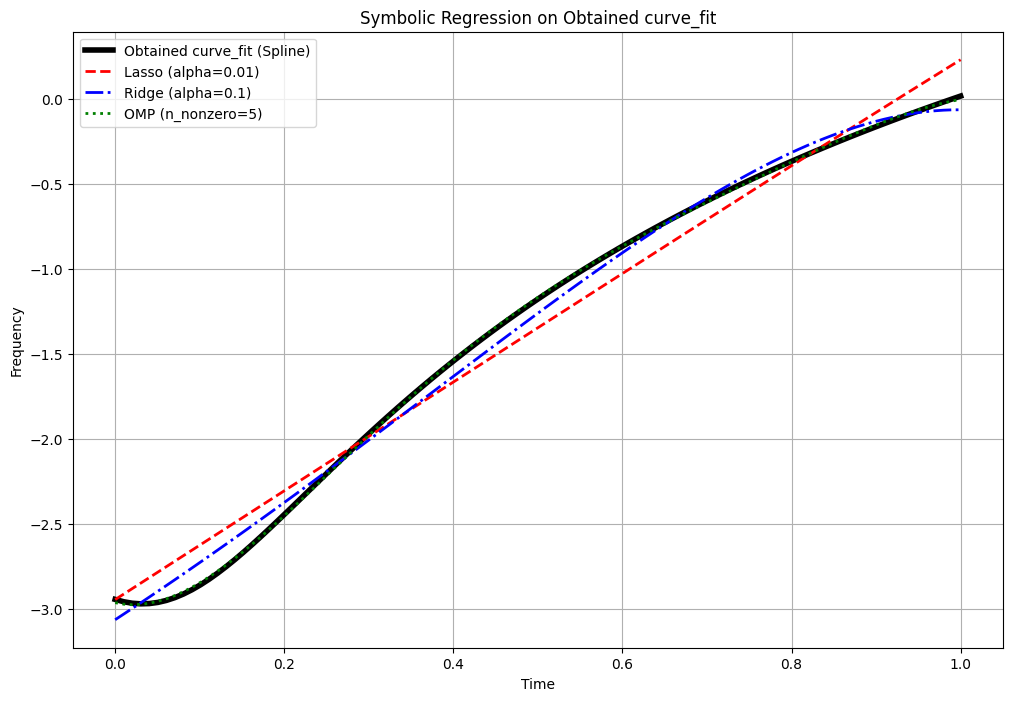


Lasso coefficients:
t: 3.1984438616438413
t^5: -0.024060556668418914

Ridge coefficients:
t: 3.2614186927988893
t^2: 1.0004842871623392
t^3: -0.23050507738284126
t^4: -0.5609442839268762
t^5: -0.4719215505972013

OMP coefficients:
t: -1.150569507028835
t^2: 28.901799006323927
t^3: -62.40731401676136
t^4: 56.663729594251755
t^5: -19.048557376281522

R² scores:
Lasso: 0.9803849392536722
Ridge: 0.9951265095729381
OMP: 0.9999226436265026


In [24]:
from sklearn.linear_model import Lasso, Ridge, OrthogonalMatchingPursuit  
from sklearn.preprocessing import PolynomialFeatures  
from sklearn.metrics import r2_score  
  
# Sample points from the obtained curve_fit  
t_sample = np.linspace(0, 1, 100)  
y_sample = curve_fit(t_sample)  
#t_sample = np.log(t_sample)
y_sample = np.log(y_sample)
# Create polynomial features (degree 5)  
poly_degree = 5  
poly = PolynomialFeatures(degree=poly_degree, include_bias=True)  
X_poly = poly.fit_transform(t_sample.reshape(-1, 1))  
  
# Prepare regression models  
n_features = X_poly.shape[1]  
n_nonzero_coefs = min(5, n_features)  # ensure valid number for OMP  
  
lasso_alpha = 0.01  
ridge_alpha = 0.1  
  
lasso = Lasso(alpha=lasso_alpha, max_iter=10000)  
ridge = Ridge(alpha=ridge_alpha)  
omp = OrthogonalMatchingPursuit(n_nonzero_coefs=n_nonzero_coefs)  
  
# Fit the models on the sampled curve data  
lasso.fit(X_poly, y_sample)  
ridge.fit(X_poly, y_sample)  
omp.fit(X_poly, y_sample)  
  
# Generate predictions using these models  
y_lasso = lasso.predict(X_poly)  
y_ridge = ridge.predict(X_poly)  
y_omp = omp.predict(X_poly)  
  
# Plot the symbolic regression results alongside the original curve_fit  
plt.figure(figsize=(12, 8))  
plt.plot(t_sample, y_sample, 'k', linewidth=4, label='Obtained curve_fit (Spline)')  
plt.plot(t_sample, y_lasso, 'r--', linewidth=2, label='Lasso (alpha=' + str(lasso_alpha) + ')')  
plt.plot(t_sample, y_ridge, 'b-.', linewidth=2, label='Ridge (alpha=' + str(ridge_alpha) + ')')  
plt.plot(t_sample, y_omp, 'g:', linewidth=2, label='OMP (n_nonzero=' + str(n_nonzero_coefs) + ')')  
plt.xlabel('Time')  
plt.ylabel('Frequency')  
plt.title('Symbolic Regression on Obtained curve_fit')  
plt.legend()  
plt.grid(True)  
plt.show()  
  
# Print the coefficients for each regression model  
feature_names = poly.get_feature_names_out(['t'])  
  
print("\nLasso coefficients:")  
for name, coef in zip(feature_names, lasso.coef_):  
    if abs(coef) > 1e-10:  
        print(name + ": " + str(coef))  
          
print("\nRidge coefficients:")  
for name, coef in zip(feature_names, ridge.coef_):  
    if abs(coef) > 1e-10:  
        print(name + ": " + str(coef))  
          
print("\nOMP coefficients:")  
for name, coef in zip(feature_names, omp.coef_):  
    if abs(coef) > 1e-10:  
        print(name + ": " + str(coef))  
          
# Print R² scores for each method  
print("\nR² scores:")  
print("Lasso: " + str(r2_score(y_sample, y_lasso)))  
print("Ridge: " + str(r2_score(y_sample, y_ridge)))  
print("OMP: " + str(r2_score(y_sample, y_omp)))  
  
# ======================  
# End of Added Symbolic Regression Section  
# ======================  